# Hof Lecture | Prescriptive Analytics: Transportation Optimization
**Student solution notebook — completed exercises with answers and explanations.**

This notebook matches the Guided THINK student exercises. Each experiment already uses its requested changed setting. The displayed BEFORE reference is the original baseline, except Prescriptive Experiment 5, which compares against the network with North already added.

Run the notebook from the top to reproduce the results. Read each Notice / Explain / Decide question, then its answers and explanations. Business decisions can have more than one reasonable answer when supported by evidence. The examples explain one defensible response rather than prescribe a single wording.


## Baseline inputs and units
This version follows the **slides**, not the conflicting modified values in the source notebook.

| DC | Available units |
|---|---:|
| DC_East | 600 |
| DC_West | 500 |
| Total | 1,100 |

| Store | Required units | Source |
|---|---:|---|
| Store_A | 250 | Explicit teaching assumption to complete missing slide inputs |
| Store_B | 300 | Explicit teaching assumption to complete missing slide inputs |
| Store_C | 350 | Solution slide; the hands-on slide's “35” is inconsistent |
| Store_D | 200 | Explicit teaching assumption to complete missing slide inputs |
| Total | 1,100 | Slide total |

The slides do not specify A, B and D individually. Their split above is a transparent completion of the missing 750 units, not a recovered fact from the slides. Baseline West=500 follows from the slide's total supply of 1,100 and East=600.

Retain the source notebook's route costs:

| EUR per unit | Store_A | Store_B | Store_C | Store_D |
|---|---:|---:|---:|---:|
| DC_East | 4 | 5 | 7 | 6 |
| DC_West | 6 | 4 | 3 | 5 |

Supply is an upper bound on units shipped, not an obligation to use all capacity. Demand must be met exactly. All quantities refer to the same unspecified planning period and homogeneous product/unit. Costs are **EUR per unit**, and the total objective is **EUR**. Unlike the descriptive notebook, these costs are not EUR per shipment.

For Experiment 4, the original 32-slide deck gives North capacity=300 but no route costs. The recovered 14-slide revision explicitly supplies the teaching assumptions for North unit costs **A=5, B=4, C=4, D=5 EUR/unit**. These are new teaching assumptions; results depend on them. North is optional capacity, with no facility opening or operating cost included.


## How to approach THINK

Each THINK section starts with a result you have just produced:
1. **Notice:** describe what the table or chart shows.
2. **Explain:** connect that observation to the store or logistics problem.
3. **Decide:** suggest a next step and explain what evidence would support it.

Use the outputs already on the page. You do not need a new formula or statistical method. Where a prompt asks for a possible reason, offer a sensible idea to investigate rather than claim the output proves its cause. Different reasoned answers may be valid when they fit the evidence.


**How to use these results:** The plan follows the capacities, demands, costs and rules we supply. Before using it in practice, check that those inputs match the operation. A low displayed cost is useful only if the plan can meet the delivery requirements.



## What the model chooses
The **decision variable** `x[DC, Store]` is the number of units shipped on that route.

- **Objective:** minimize `sum(unit cost × units shipped)` across all routes.
- **Capacity constraints:** each DC's total shipments must not exceed its available capacity.
- **Demand constraints:** each store must receive exactly its required units.
- **Nonnegativity:** shipped quantities cannot be negative.
- Experiment 5 retains North capacity of 300 and adds `total shipments from DC_West <= 400`. Its BEFORE reference is the North scenario, not the original two-DC baseline.

All listed DC-to-store routes are allowed. Costs are constant per unit. The model is a continuous linear program (LP): quantities may be fractional. This particular transportation structure with integer inputs has an integral optimal solution, but the formulation does not explicitly impose integer variables. No route capacity, transit-time, emissions, stock uncertainty or multi-product interaction is modeled.

**Feasibility first:** With full route connectivity and no additional route constraints, total effective supply below total demand makes this model infeasible. This is different from an expensive but feasible solution.

**No automatic shortages:** This model requires full demand satisfaction. Ordinary unused-capacity slack cannot resolve insufficient supply. Allowing unmet demand would require explicitly introducing shortage variables, defining shortage penalties and changing the service policy; that is a different model and is not silently applied here.

**Compare costs only when both scenarios are optimal.** Signed difference = AFTER − BEFORE, in EUR. If either scenario is infeasible, the cost difference is unavailable, not zero or infinity. Alternative optimal plans can exist; assess feasibility and total cost, not only exact route quantities.

The supplied PuLP formulation is implemented here using SciPy's HiGHS LP solver, with the same objective and constraint structure. This removes the source notebook's runtime PuLP installation step. Both approaches solve the same mathematical model; the baseline inputs have intentionally changed to match the slide totals.


## Provided functions — run before the exercises

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from IPython.display import display

In [3]:
# PROVIDED FUNCTIONS — RUN THIS CELL; NO EDITS REQUIRED.

def solve_transport(dcs, stores, costs, west_limit=None):
    """Solve a continuous transport LP, preserving input tables."""
    supply = dcs.set_index("DC")["Supply"].astype(float)
    demand = stores.set_index("Store")["Demand"].astype(float)
    matrix = costs.set_index("DC").loc[supply.index, demand.index].astype(float)
    if not supply.index.is_unique or not demand.index.is_unique:
        raise ValueError("DC and store identifiers must be unique.")
    if not np.isfinite(supply).all() or not np.isfinite(demand).all():
        raise ValueError("Supply and demand must be finite.")
    if (supply < 0).any() or (demand < 0).any():
        raise ValueError("Supply and demand must be nonnegative.")
    if not np.isfinite(matrix.to_numpy()).all():
        raise ValueError("Provide a finite unit cost for every route.")
    nd, ns = len(supply), len(demand)
    c = matrix.to_numpy().ravel()
    a_supply = np.zeros((nd, nd * ns))
    for i in range(nd): a_supply[i, i*ns:(i+1)*ns] = 1
    a_demand = np.zeros((ns, nd * ns))
    for j in range(ns): a_demand[j, j::ns] = 1
    a_ub = a_supply.copy(); b_ub = supply.to_numpy().copy()
    effective = supply.copy()
    if west_limit is not None:
        if west_limit < 0 or "DC_West" not in supply.index:
            raise ValueError("West limit requires DC_West and a nonnegative limit.")
        i = list(supply.index).index("DC_West")
        a_ub = np.vstack([a_ub, a_supply[i]])
        b_ub = np.append(b_ub, float(west_limit))
        effective.loc["DC_West"] = min(supply.loc["DC_West"], west_limit)
    result = linprog(c, A_ub=a_ub, b_ub=b_ub,
                     A_eq=a_demand, b_eq=demand.to_numpy(),
                     bounds=(0, None), method="highs")
    status = {0: "Optimal", 1: "Limit reached", 2: "Infeasible", 3: "Unbounded", 4: "Solver error"}.get(result.status, "Unknown")
    output = {"status": status, "solver_message": result.message,
              "capacity": float(supply.sum()), "effective_capacity": float(effective.sum()),
              "demand": float(demand.sum()),
              "capacity_gap": max(0.0, float(demand.sum()-effective.sum())),
              "total_cost": None, "flows": None, "costs": matrix,
              "supply": supply, "effective_supply": effective, "store_demand": demand}
    if not result.success:
        return output  # No objective or shipment values from an unsuccessful solve.
    flows = pd.DataFrame(result.x.reshape(nd, ns), index=supply.index, columns=demand.index)
    flows[abs(flows) < 1e-8] = 0
    assert (flows.to_numpy() >= -1e-7).all()
    assert np.allclose(flows.sum(axis=0), demand, atol=1e-7)
    assert (flows.sum(axis=1) <= effective + 1e-7).all()
    assert np.isclose((flows*matrix).to_numpy().sum(), result.fun)
    output.update(total_cost=float((flows*matrix).to_numpy().sum()), flows=flows)
    return output

def show_plan(result, title):
    print(title, "| Status:", result["status"])
    display(pd.DataFrame({"Measure": ["Available capacity", "Effective capacity after policy limits", "Required demand", "Aggregate capacity shortfall"],
                          "Units": [result["capacity"], result["effective_capacity"], result["demand"], result["capacity_gap"]]}))
    if result["status"] != "Optimal":
        print("No feasible optimal shipment plan is reported. Total cost is unavailable.")
        print(result["solver_message"])
        return
    print(f"Minimum transport cost: EUR {result['total_cost']:.2f}")
    display(result["flows"].round(3))
    display(pd.DataFrame({"Capacity": result["supply"], "Effective capacity": result["effective_supply"],
                          "Shipped": result["flows"].sum(axis=1),
                          "Unused effective capacity": result["effective_supply"]-result["flows"].sum(axis=1)}).round(3))
    display(pd.DataFrame({"Required": result["store_demand"], "Received": result["flows"].sum(axis=0)}).round(3))
    ax = result["flows"].T.plot.bar(stacked=True, figsize=(7, 3.5))
    ax.set_title(title + " — optimal shipments")
    ax.set_xlabel("Store"); ax.set_ylabel("Units in the planning period")
    ax.tick_params(axis="x", rotation=0)
    ax.figure.tight_layout(); plt.show()

def compare(before, after, title):
    table = pd.DataFrame({"Measure": ["Status", "Effective capacity (units)", "Demand (units)", "Minimum transport cost (EUR)"],
        "BEFORE": [before["status"], before["effective_capacity"], before["demand"], before["total_cost"] if before["total_cost"] is not None else "Unavailable"],
        "AFTER": [after["status"], after["effective_capacity"], after["demand"], after["total_cost"] if after["total_cost"] is not None else "Unavailable"]})
    display(table)
    if before["status"] == after["status"] == "Optimal":
        print(f"Signed cost change (AFTER - BEFORE): EUR {after['total_cost']-before['total_cost']:+.2f}")
    else:
        print("Cost difference unavailable: both scenarios must have valid optimal solutions.")
    show_plan(after, title)

def capacity_scenario(dcs, stores, costs, east_supply):
    x = dcs.copy(deep=True)
    x.loc[x.DC == "DC_East", "Supply"] = east_supply
    return solve_transport(x, stores, costs)

def demand_scenario(dcs, stores, costs, store_c_demand):
    x = stores.copy(deep=True)
    x.loc[x.Store == "Store_C", "Demand"] = store_c_demand
    return solve_transport(dcs, x, costs)

def cost_scenario(dcs, stores, costs, west_extra):
    x = costs.copy(deep=True)
    store_columns = list(stores.Store)
    x.loc[x.DC == "DC_West", store_columns] += west_extra
    return solve_transport(dcs, stores, x)

def north_scenario(dcs, stores, costs, north_capacity, west_limit=None):
    # Explicit additional teaching assumptions: EUR per unit on North routes.
    # The recovered 14-slide revision also explicitly lists these teaching costs.
    north_costs = {"Store_A": 5.0, "Store_B": 4.0, "Store_C": 4.0, "Store_D": 5.0}
    x = pd.concat([dcs.copy(), pd.DataFrame({"DC": ["DC_North"], "Supply": [north_capacity]})], ignore_index=True)
    y = pd.concat([costs.copy(), pd.DataFrame([{"DC": "DC_North", **north_costs}])], ignore_index=True)
    return solve_transport(x, stores, y, west_limit=west_limit)


## Baseline — inspect BEFORE the experiments
Read capacities, demands and the unit-cost matrix before interpreting the plan.

,DC,Supply
0,DC_East,600
1,DC_West,500


,Store,Demand
0,Store_A,250
1,Store_B,300
2,Store_C,350
3,Store_D,200


,DC,Store_A,Store_B,Store_C,Store_D
0,DC_East,4.0,5.0,7.0,6.0
1,DC_West,6.0,4.0,3.0,5.0


BASELINE | Status: Optimal


,Measure,Units
0,Available capacity,1100.0
1,Effective capacity after policy limits,1100.0
2,Required demand,1100.0
3,Aggregate capacity shortfall,0.0


Minimum transport cost: EUR 4600.00


Store,Store_A,Store_B,Store_C,Store_D
DC,,,,
DC_East,250.0,300.0,0.0,50.0
DC_West,0.0,0.0,350.0,150.0


,Capacity,Effective capacity,Shipped,Unused effective capacity
DC,,,,
DC_East,600.0,600.0,600.0,0.0
DC_West,500.0,500.0,500.0,0.0


,Required,Received
Store,,
Store_A,250.0,250.0
Store_B,300.0,300.0
Store_C,350.0,350.0
Store_D,200.0,200.0


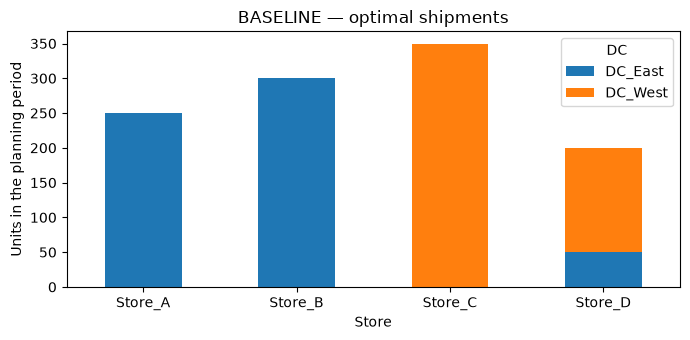

In [4]:
# Slide-aligned baseline. Capacities and total demand come from the slides.
# Assumed missing demand split: A=250, B=300, D=200 (sum 750).
baseline_dcs = pd.DataFrame({"DC": ["DC_East", "DC_West"], "Supply": [600, 500]})
baseline_stores = pd.DataFrame({"Store": ["Store_A", "Store_B", "Store_C", "Store_D"],
                                "Demand": [250, 300, 350, 200]})
# Original notebook's route unit costs retained (EUR per unit).
baseline_costs = pd.DataFrame({"DC": ["DC_East", "DC_West"],
    "Store_A": [4., 6.], "Store_B": [5., 4.], "Store_C": [7., 3.], "Store_D": [6., 5.]})

display(baseline_dcs)
display(baseline_stores)
display(baseline_costs)
baseline_result = solve_transport(baseline_dcs, baseline_stores, baseline_costs)
show_plan(baseline_result, "BASELINE")  # <-- OBSERVE OUTPUT

**THINK — use the result you can see**

Read the shipment plan, the DC capacity table and the store Required/Received table.

1. **Notice:** Choose one store. Does the displayed plan deliver the units it requires? Point to its Required and Received values.

2. **Explain:** Look at the unused capacity for East and West. If a store asked for more units in this same planning period, what concern would you raise?

3. **Decide:** What has the model decided for the planner? Explain using one route in the shipment plan, then name one practical issue the planner should check before sending the goods.

**Worked answers appear below.**


### Answers and explanations

**Notice — answer:** For example, Store_A requires 250 units and receives 250. All stores have matching Required and Received values in the baseline plan.

**Explain — answer:** Both East and West have zero unused capacity in the baseline. Additional demand in the same period would require more capacity or a changed delivery requirement.

**Decide — answer:** The model chooses how many units travel on each DC-to-store route. In the displayed baseline, East sends 250 units to A. Before dispatch, a planner might check vehicle availability or delivery timing, which the exercise does not model.

## Experiment 1 — Capacity reduction
**Business question:** What happens when total capacity no longer covers demand?

**BEFORE:** DC_East capacity = 600.

**CHANGE:** Set EAST_SUPPLY from 600 to 500. Keep West=500 and all demands unchanged. Solve and inspect status before looking for a cost.

**AFTER:** Check status and capacity/demand first. Interpret costs and flows only for an optimal solution.

In [5]:
EAST_SUPPLY = 500  # <-- CHANGE HERE: 600 -> 500 units
capacity_result = capacity_scenario(baseline_dcs, baseline_stores, baseline_costs, EAST_SUPPLY)
compare(baseline_result, capacity_result, "Experiment 1 — Capacity reduction")  # <-- OBSERVE OUTPUT

,Measure,BEFORE,AFTER
0,Status,Optimal,Infeasible
1,Effective capacity (units),1100.0,1000.0
2,Demand (units),1100.0,1100.0
3,Minimum transport cost (EUR),4600.0,Unavailable


Cost difference unavailable: both scenarios must have valid optimal solutions.
Experiment 1 — Capacity reduction | Status: Infeasible


,Measure,Units
0,Available capacity,1000.0
1,Effective capacity after policy limits,1000.0
2,Required demand,1100.0
3,Aggregate capacity shortfall,100.0


No feasible optimal shipment plan is reported. Total cost is unavailable.
The problem is infeasible. (HiGHS Status 8: model_status is Infeasible; primal_status is None)


**THINK — use the result you can see**

First set EAST_SUPPLY=500 and rerun. Read Status, Effective capacity, Required demand and Aggregate capacity shortfall. Infeasible means no plan can meet all the current rules.

1. **Notice:** What does the status say? Use the displayed capacity and demand values to explain the problem to a warehouse manager.

2. **Explain:** Could moving the same goods between different routes solve this problem? Explain using the total amount the DCs can ship, rather than route prices.

3. **Decide:** What practical response would you investigate first: securing extra capacity or discussing delivery timing with stores? Choose one, explain the trade-off, and identify which model input or delivery requirement would need to change.

**Worked answers appear below.**


### Answers and explanations

**Notice — answer:** Status is Infeasible. Effective capacity is 1,000 units and required demand is 1,100, leaving a 100-unit shortfall. The current rules cannot all be met.

**Explain — answer:** No. Changing routes moves the same available units between stores; it cannot create the missing 100 units. Lower route prices also cannot fix the capacity shortage.

**Decide — answer:** One possible response is to investigate extra capacity. Extra capacity changes the available supply but may cost more. Negotiating delivery timing changes what must arrive within this planning period and may affect service. The notebook keeps exact demand until a new service policy is explicitly introduced.

## Experiment 2 — Demand spike
**Business question:** Can existing capacity serve an additional 100 units at Store_C?

**BEFORE:** Store_C demand = 350, consistent with the solution slide.

**CHANGE:** Set STORE_C_DEMAND from 350 to 450. Keep all capacities and other store demands fixed. The hands-on slide's starting “35” must be corrected to “350.”

**AFTER:** Check status and capacity/demand first. Interpret costs and flows only for an optimal solution.

In [6]:
STORE_C_DEMAND = 450  # <-- CHANGE HERE: 350 -> 450 units
demand_result = demand_scenario(baseline_dcs, baseline_stores, baseline_costs, STORE_C_DEMAND)
compare(baseline_result, demand_result, "Experiment 2 — Demand spike")  # <-- OBSERVE OUTPUT

,Measure,BEFORE,AFTER
0,Status,Optimal,Infeasible
1,Effective capacity (units),1100.0,1100.0
2,Demand (units),1100.0,1200.0
3,Minimum transport cost (EUR),4600.0,Unavailable


Cost difference unavailable: both scenarios must have valid optimal solutions.
Experiment 2 — Demand spike | Status: Infeasible


,Measure,Units
0,Available capacity,1100.0
1,Effective capacity after policy limits,1100.0
2,Required demand,1200.0
3,Aggregate capacity shortfall,100.0


No feasible optimal shipment plan is reported. Total cost is unavailable.
The problem is infeasible. (HiGHS Status 8: model_status is Infeasible; primal_status is None)


**THINK — use the result you can see**

First set STORE_C_DEMAND=450 and rerun. Other store demands and DC capacities stay unchanged. Read the status and the displayed shortfall.

1. **Notice:** What problem appears when Store_C asks for more units? Describe it using the displayed demand and capacity totals.

2. **Explain:** A manager suggests taking units intended for Store_A and sending them to Store_C. Would that satisfy every store's stated requirement? Explain what would happen to Store_A.

3. **Decide:** Before promising the extra units to Store_C, what would you check or discuss with the operation? Propose one concrete next step and explain how it could address the shortfall.

**Worked answers appear below.**


### Answers and explanations

**Notice — answer:** The status becomes Infeasible. Demand rises to 1,200 units while capacity stays at 1,100. The plan is short by 100 units.

**Explain — answer:** Moving units from A to C would leave A below its stated requirement. It does not meet the exercise rule that every store receives its full demand.

**Decide — answer:** For example, check whether an additional supply source can deliver within the period, and confirm any capacity and cost before promising delivery. Another option is to discuss revised delivery timing with the customer. That changes the service requirement for this period and needs explicit agreement.

## Experiment 3 — Cost adjustment
**Business question:** Does a uniform West unit-cost increase necessarily change the allocation?

**BEFORE:** No added West route cost.

**CHANGE:** Set WEST_EXTRA_COST from 0 to 2 EUR/unit on every West route. Keep capacities and demands fixed.

**AFTER:** Check status and capacity/demand first. Interpret costs and flows only for an optimal solution.

,Measure,BEFORE,AFTER
0,Status,Optimal,Optimal
1,Effective capacity (units),1100.0,1100.0
2,Demand (units),1100.0,1100.0
3,Minimum transport cost (EUR),4600.0,5600.0


Signed cost change (AFTER - BEFORE): EUR +1000.00
Experiment 3 — West route costs | Status: Optimal


,Measure,Units
0,Available capacity,1100.0
1,Effective capacity after policy limits,1100.0
2,Required demand,1100.0
3,Aggregate capacity shortfall,0.0


Minimum transport cost: EUR 5600.00


Store,Store_A,Store_B,Store_C,Store_D
DC,,,,
DC_East,250.0,300.0,0.0,50.0
DC_West,0.0,0.0,350.0,150.0


,Capacity,Effective capacity,Shipped,Unused effective capacity
DC,,,,
DC_East,600.0,600.0,600.0,0.0
DC_West,500.0,500.0,500.0,0.0


,Required,Received
Store,,
Store_A,250.0,250.0
Store_B,300.0,300.0
Store_C,350.0,350.0
Store_D,200.0,200.0


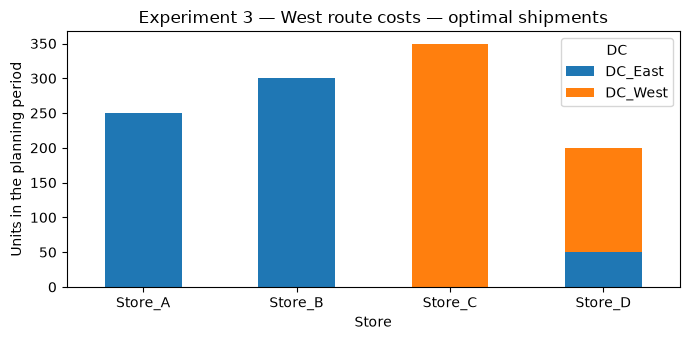

In [7]:
WEST_EXTRA_COST = 2  # <-- CHANGE HERE: 0 -> 2 EUR/unit
cost_result = cost_scenario(baseline_dcs, baseline_stores, baseline_costs, WEST_EXTRA_COST)
compare(baseline_result, cost_result, "Experiment 3 — West route costs")  # <-- OBSERVE OUTPUT

**THINK — use the result you can see**

First set WEST_EXTRA_COST=2 and rerun. Read the printed cost change and the DC Shipped/Unused capacity table. The surcharge applies to every unit shipped from West.

1. **Notice:** What happened to minimum transport cost? Read the displayed BEFORE, AFTER and signed cost change. No additional cost calculation is needed.

2. **Explain:** Why can the planner not simply stop using West when its prices rise? Use the demand requirement and the available capacity at East to explain.

3. **Decide:** To reduce the higher bill, which possibility would you investigate: negotiating West's price or obtaining more capacity elsewhere? Choose one and describe what you would change in a new model run to evaluate it.

**Worked answers appear below.**


### Answers and explanations

**Notice — answer:** Minimum transport cost rises from EUR 4,600 to EUR 5,600. The displayed signed increase is EUR 1,000.

**Explain — answer:** East can ship only 600 units against total demand of 1,100. West must provide the remaining 500, so it cannot simply be dropped. In this balanced network the uniform West surcharge raises every feasible plan's cost by the same amount.

**Decide — answer:** One possible response is to negotiate West’s price. Negotiating means testing a different West unit cost. More capacity elsewhere means changing supply and, if a new location is proposed, adding its route costs. Compare the new feasible plan and include relevant extra costs before recommending it.

## Experiment 4 — New DC added
**Business question:** Can optional North capacity lower transport cost under the stated route costs?

**BEFORE:** North capacity = 0; existing East/West network unchanged.

**CHANGE:** Set NORTH_SUPPLY from 0 to 300. North route costs are explicitly assumed A=5, B=4, C=4, D=5 EUR/unit. Keep original demand fixed.

**AFTER:** Check status and capacity/demand first. Interpret costs and flows only for an optimal solution.

,Measure,BEFORE,AFTER
0,Status,Optimal,Optimal
1,Effective capacity (units),1100.0,1400.0
2,Demand (units),1100.0,1100.0
3,Minimum transport cost (EUR),4600.0,4300.0


Signed cost change (AFTER - BEFORE): EUR -300.00
Experiment 4 — New North DC | Status: Optimal


,Measure,Units
0,Available capacity,1400.0
1,Effective capacity after policy limits,1400.0
2,Required demand,1100.0
3,Aggregate capacity shortfall,0.0


Minimum transport cost: EUR 4300.00


Store,Store_A,Store_B,Store_C,Store_D
DC,,,,
DC_East,250.0,50.0,0.0,0.0
DC_West,0.0,150.0,350.0,0.0
DC_North,0.0,100.0,0.0,200.0


,Capacity,Effective capacity,Shipped,Unused effective capacity
DC,,,,
DC_East,600.0,600.0,300.0,300.0
DC_West,500.0,500.0,500.0,0.0
DC_North,300.0,300.0,300.0,0.0


,Required,Received
Store,,
Store_A,250.0,250.0
Store_B,300.0,300.0
Store_C,350.0,350.0
Store_D,200.0,200.0


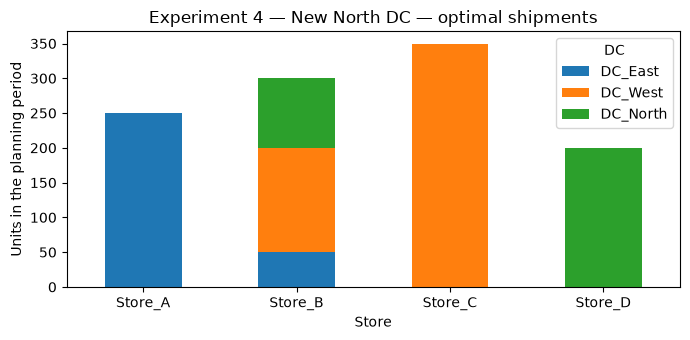

In [8]:
NORTH_SUPPLY = 300  # <-- CHANGE HERE: 0 -> 300 units
north_result = north_scenario(baseline_dcs, baseline_stores, baseline_costs, NORTH_SUPPLY)
compare(baseline_result, north_result, "Experiment 4 — New North DC")  # <-- OBSERVE OUTPUT

**THINK — use the result you can see**

First set NORTH_SUPPLY=300 and rerun. Read the cost comparison and North's Shipped/Unused capacity values. The model includes transport costs, while facility opening and operating costs are outside this exercise.

1. **Notice:** What happens to minimum transport cost after North becomes available? Does the displayed plan use all, some or none of North's capacity?

2. **Explain:** Choose one store that receives units from North in the displayed plan. Compare the route costs to that store. How might these prices help explain the plan? Remember the other DCs also have capacity limits.

3. **Decide:** The manager wants to open North based on the transport saving alone. What additional cost or practical requirement would you ask about first? Explain how it might affect the decision.

**Worked answers appear below.**


### Answers and explanations

**Notice — answer:** Minimum transport cost falls from EUR 4,600 to EUR 4,300. In the executed plan North ships 300 units, using all its capacity. Alternative optimal plans can distribute some route flows differently while meeting all requirements at the same minimum cost.

**Explain — answer:** In the displayed plan North supplies B and D. Its B cost of EUR 4/unit is below East's 5 and tied with West's 4; its D cost of 5 is below East's 6 and tied with West's 5. Capacity limits across the network matter as well as individual route prices.

**Decide — answer:** For example, ask about rent, staff or facility setup costs. A EUR 300 transport saving could be outweighed by these costs in the same planning period. Other valid issues include delivery time or readiness to operate.

## Experiment 5 — Combined constraint: North plus West cap
**Business question:** How does a West policy limit change the expanded network plan?

**BEFORE:** Retain North capacity=300. West shipment limit=500, equivalent to its original capacity.

**CHANGE:** Set WEST_SHIPMENT_LIMIT from 500 to 400, retaining East=600, North=300 and unchanged baseline demand. Compare against the North-added network from Experiment 4. The reference is recreated here so the cell can run independently after setup.

**AFTER:** Check status and capacity/demand first. Interpret costs and flows only for an optimal solution.

,Measure,BEFORE,AFTER
0,Status,Optimal,Optimal
1,Effective capacity (units),1400.0,1300.0
2,Demand (units),1100.0,1100.0
3,Minimum transport cost (EUR),4300.0,4400.0


Signed cost change (AFTER - BEFORE): EUR +100.00
Experiment 5 — North plus West cap | Status: Optimal


,Measure,Units
0,Available capacity,1400.0
1,Effective capacity after policy limits,1300.0
2,Required demand,1100.0
3,Aggregate capacity shortfall,0.0


Minimum transport cost: EUR 4400.00


Store,Store_A,Store_B,Store_C,Store_D
DC,,,,
DC_East,250.0,150.0,0.0,0.0
DC_West,0.0,50.0,350.0,0.0
DC_North,0.0,100.0,0.0,200.0


,Capacity,Effective capacity,Shipped,Unused effective capacity
DC,,,,
DC_East,600.0,600.0,400.0,200.0
DC_West,500.0,400.0,400.0,0.0
DC_North,300.0,300.0,300.0,0.0


,Required,Received
Store,,
Store_A,250.0,250.0
Store_B,300.0,300.0
Store_C,350.0,350.0
Store_D,200.0,200.0


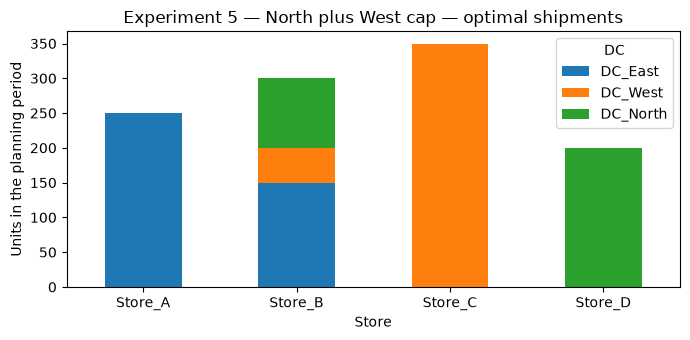

In [9]:
WEST_SHIPMENT_LIMIT = 400  # <-- CHANGE HERE: 500 -> 400 units
north_reference = north_scenario(baseline_dcs, baseline_stores, baseline_costs, 300)
west_cap_result = north_scenario(baseline_dcs, baseline_stores, baseline_costs, 300, west_limit=WEST_SHIPMENT_LIMIT)
compare(north_reference, west_cap_result, "Experiment 5 — North plus West cap")  # <-- OBSERVE OUTPUT

**THINK — use the result you can see**

First set WEST_SHIPMENT_LIMIT=400 and rerun. North remains available with capacity 300. The BEFORE reference here is the network with North already added.

1. **Notice:** After the West limit changes, can the model still meet demand? What happens to cost compared with the North-added reference? Read the displayed status and cost change.

2. **Explain:** Compare West's and North's shipments in the BEFORE and AFTER outputs. How does having North available help the planner respond to the West limit?

3. **Decide:** Suppose the West limit protects staff from excessive workload. How would you explain the extra transport cost to management? Identify the operational benefit you would want to check alongside that cost.

**Worked answers appear below.**


### Answers and explanations

**Notice — answer:** The status remains Optimal. Cost rises from EUR 4,300 to EUR 4,400, an extra EUR 100 relative to the North-added network.

**Explain — answer:** In the executed plans West falls from 500 to 400 units, North stays at 300 and East rises from 300 to 400. North need not increase its shipments to be useful: its existing capacity keeps the expanded network able to satisfy demand. Without North, East 600 plus West 400 would be insufficient. Alternative optimal route allocations are possible.

**Decide — answer:** The extra EUR 100 is the model's transport-cost trade-off for this policy, relative to the North-added reference. Check whether the limit actually reduces workload or improves working conditions. The LP does not itself measure staff wellbeing, and 400 shipped units is only the policy assumption.

## Final comparison and explanation

| Experiment | Outcome | Cost change |
|---|---|---|
| East 500 | Infeasible: 100-unit shortfall | Unavailable |
| C demand 450 | Infeasible: 100-unit shortfall | Unavailable |
| West +2 | Optimal: EUR 5,600 | +EUR 1,000 versus baseline |
| North 300 | Optimal: EUR 4,300 | -EUR 300 versus baseline |
| North plus West cap 400 | Optimal: EUR 4,400 | +EUR 100 versus North reference |

An example final reflection is: North reduces modeled transport cost, but the manager should check facility operating costs before deciding to use or open that location. Accept other evidence-based reflections. Infeasible scenarios have no valid cost or plan to compare.
